# 1. Revisión inicial del conjunto de datos MiBici 2024

Actividades: **1.1 Verificación de archivos**, **1.2 Inspección de estructura**, **1.3 Volumen real de registros y estaciones**. Este notebook **excluye los datos de 2023**. La nomenclatura proporcionada corresponde a septiembre de 2026, no al año de los viajes.

**Datos locales:** Los CSV de MiBici no se incorporan al repositorio Git. Las secciones 2.x se ejecutan sobre los archivos originales en `data/raw/` y no modifican esos archivos.

In [1]:

from pathlib import Path
import pandas as pd
import hashlib

# Identificar el directorio actual de Jupyter
CURRENT_DIR = Path.cwd().resolve()

# Detectar la raiz del proyecto Cookiecutter
if (CURRENT_DIR / "data" / "raw").is_dir():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data" / "raw").is_dir():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        f"No se encontro data/raw desde {CURRENT_DIR}"
    )

# Definir las rutas de los datasets
DATA_DIR = PROJECT_ROOT / "data" / "raw"

FILES = sorted(DATA_DIR.glob("datos_abiertos_2024_*.csv"))
STATIONS_FILE = DATA_DIR / "nomenclatura_2026_09.csv"

# Mostrar diagnostico
print("Directorio de ejecucion:", CURRENT_DIR)
print("Raiz del proyecto:", PROJECT_ROOT)
print("Directorio de datos:", DATA_DIR)
print("Directorio existe:", DATA_DIR.is_dir())
print("Archivos mensuales encontrados:", len(FILES))
print("Nomenclatura encontrada:", STATIONS_FILE.is_file())

# Validaciones
assert len(FILES) == 12, (
    f"Se requieren doce CSV de 2024; encontrados: {len(FILES)}"
)

assert STATIONS_FILE.is_file(), (
    "Falta el CSV de nomenclatura"
)

print("\nArchivos mensuales detectados:")
for archivo in FILES:
    print(" -", archivo.name)

print("\nValidacion completada correctamente.")


Directorio de ejecucion: /Users/josemtzromero01/Documents/Maestria-MNA/MLOps/week5/TC5061-Proyecto-Equipo15/notebooks
Raiz del proyecto: /Users/josemtzromero01/Documents/Maestria-MNA/MLOps/week5/TC5061-Proyecto-Equipo15
Directorio de datos: /Users/josemtzromero01/Documents/Maestria-MNA/MLOps/week5/TC5061-Proyecto-Equipo15/data/raw
Directorio existe: True
Archivos mensuales encontrados: 12
Nomenclatura encontrada: True

Archivos mensuales detectados:
 - datos_abiertos_2024_01.csv
 - datos_abiertos_2024_02.csv
 - datos_abiertos_2024_03.csv
 - datos_abiertos_2024_04.csv
 - datos_abiertos_2024_05.csv
 - datos_abiertos_2024_06.csv
 - datos_abiertos_2024_07.csv
 - datos_abiertos_2024_08.csv
 - datos_abiertos_2024_09.csv
 - datos_abiertos_2024_10.csv
 - datos_abiertos_2024_11.csv
 - datos_abiertos_2024_12.csv

Validacion completada correctamente.


## 1.1 Verificación de archivos
Se valida existencia, apertura, tamaño y huella SHA-256. Un hash permite identificar los bytes analizados; no sustituye el control de calidad.

In [2]:
def sha256_archivo(path, tam_bloque=1024 * 1024):
    """Calcula SHA-256 sin leer todo el CSV en memoria."""
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for bloque in iter(lambda: stream.read(tam_bloque), b""):
            digest.update(bloque)
    return digest.hexdigest()

archivos = []
for path in FILES:
    with path.open("rb") as f:
        head = f.read(512)
    # Las fuentes combinan Latin-1 y UTF-8 para sus encabezados
    enc = "utf-8" if "2024_07" in path.name else "latin1"
    header = pd.read_csv(path, nrows=0, encoding=enc).columns.tolist()
    archivos.append({"archivo": path.name, "bytes": path.stat().st_size, "columnas": len(header), "encoding_lectura": enc, "sha256": sha256_archivo(path)})
display(pd.DataFrame(archivos))

,archivo,bytes,columnas,encoding_lectura,sha256
0,datos_abiertos_2024_01.csv,33908887,8,latin1,01d1c136609df006410a2f8d9b925f20991e28cfe0c882...
1,datos_abiertos_2024_02.csv,33242518,8,latin1,78254eb6b99b9b9fb46cc5bb58fd54bc9fed681d9c2241...
2,datos_abiertos_2024_03.csv,33824245,8,latin1,6c45a6ec1f136c58bfcb6fdd385c4e1ac2f4b887d0413d...
3,datos_abiertos_2024_04.csv,35119762,8,latin1,d60f68ebc083b0cea29d6e7a0e18eba95c4582220a7971...
4,datos_abiertos_2024_05.csv,35597286,8,latin1,21288117db70fad4e475cc5fb6acab174a84c09749170c...
5,datos_abiertos_2024_06.csv,31623557,8,latin1,cd073cecc62cd7a358b1a54f342ad78ca0fa6a94d039e9...
6,datos_abiertos_2024_07.csv,31551829,8,utf-8,0d6dab9e3c5d1ed6f43f5c3ce65aea9ea51cd151c62cd8...
7,datos_abiertos_2024_08.csv,34220772,8,latin1,4d6bd19355c8e8a0829b280ce8844bd2c1b82e5e3ffcfc...
8,datos_abiertos_2024_09.csv,25448981,8,latin1,d4f7653879861abb67ffda890dd79d0cc8b71edbb04316...
9,datos_abiertos_2024_10.csv,27315974,8,latin1,9146623af19ea413a817a5077048b605ac5f4cd1bbe65f...


## 1.2 Inspección del esquema y los formatos de fecha
Todos los archivos contienen ocho campos en el mismo orden. Algunos nombres de campo de año de nacimiento tienen caracteres alterados por codificación; normalizamos nombres por posición solo después de comprobar las ocho columnas. Septiembre y octubre emplean fechas día/mes/año con precisión de minutos; otros meses emplean año-mes-día con segundos.

In [3]:
schema = []
for path in FILES:
    mes = int(path.stem[-2:])
    enc = "utf-8" if mes == 7 else "latin1"
    example = pd.read_csv(path, nrows=2, encoding=enc, dtype=str)
    schema.append({"mes":mes,"columnas":list(example.columns),"inicio_ejemplo":example.iloc[0,4],"fin_ejemplo":example.iloc[0,5]})
pd.DataFrame(schema)

,mes,columnas,inicio_ejemplo,fin_ejemplo
0,1,"[Viaje_Id, Usuario_Id, Genero, Año_de_nacimien...",2024-01-01 00:05:25,2024-01-01 00:29:37
1,2,"[Viaje_Id, Usuario_Id, Genero, A}äe_nacimiento...",2024-02-01 00:01:46,2024-02-01 00:13:00
2,3,"[Viaje_Id, Usuario_Id, Genero, Año_de_nacimien...",2024-03-01 00:00:22,2024-03-01 00:20:38
3,4,"[Viaje_Id, Usuario_Id, Genero, Año_de_nacimien...",2024-04-01 00:00:48,2024-04-01 00:05:06
4,5,"[Viaje_Id, Usuario_Id, Genero, A}äe_nacimiento...",2024-05-01 00:01:35,2024-05-01 00:09:08
5,6,"[Viaje_Id, Usuario_Id, Genero, Año_de_nacimien...",2024-06-01 00:00:17,2024-06-01 00:08:09
6,7,"[Viaje_Id, Usuario_Id, Genero, Año_de_nacimien...",2024-07-01 00:00:34,2024-07-01 00:09:40
7,8,"[Viaje_Id, Usuario_Id, Genero, Año_de_nacimien...",2024-08-01 00:00:09,2024-08-01 00:14:18
8,9,"[Viaje_Id, Usuario_Id, Genero, Año_de_nacimien...",01/09/2024 0:00,01/09/2024 0:07
9,10,"[Viaje_Id, Usuario_Id, Genero, Año_de_nacimien...",01/10/2024 0:00,01/10/2024 0:21


## 1.3 Conteos reales por mes y de estaciones distintas
Procesamiento por bloques para no cargar los millones de registros de una sola vez. Se cuentan estaciones únicas entre origen y destino; esta cantidad corresponde a identificadores observados en viajes, no al inventario de estaciones activas.

In [4]:
salida = []
origins, destinations = set(),set()
for path in FILES:
    mes = int(path.stem[-2:]); enc = "utf-8" if mes == 7 else "latin1"
    total = 0; estaciones_mes = set()
    for chunk in pd.read_csv(path, encoding=enc, dtype=str, chunksize=100_000):
        assert len(chunk.columns) == 8
        chunk.columns = ["viaje_id","usuario_id","genero","anio_nacimiento","inicio","fin","origen","destino"]
        total += len(chunk)
        o = set(chunk.origen.dropna()); d=set(chunk.destino.dropna())
        origins.update(o); destinations.update(d); estaciones_mes.update(o|d)
    salida.append({"mes":mes,"viajes":total,"estaciones_observadas":len(estaciones_mes)})
resumen = pd.DataFrame(salida)
display(resumen)
print("Total de registros:", resumen.viajes.sum())
print("Estaciones distintas (origen o destino):",len(origins|destinations))
nomenclatura = pd.read_csv(STATIONS_FILE,dtype=str)
print("IDs en nomenclatura septiembre 2026:",nomenclatura.id.nunique())
print("Estaciones de viajes 2024 no encontradas en nomenclatura:",len((origins|destinations)-set(nomenclatura.id)))

,mes,viajes,estaciones_observadas
0,1,391591,360
1,2,383732,360
2,3,390513,360
3,4,405308,360
4,5,410806,360
5,6,365000,362
6,7,364177,360
7,8,394894,360
8,9,390072,360
9,10,418690,360


Total de registros: 4645921
Estaciones distintas (origen o destino): 370
IDs en nomenclatura septiembre 2026: 484
Estaciones de viajes 2024 no encontradas en nomenclatura: 0


## 1.4 Hallazgos iniciales y limitaciones
- La presencia y la lectura de archivos se verifican; esto no implica que todos los viajes sean válidos operativamente.
- La nomenclatura 2026 permite vincular IDs de 2024, pero **no prueba** que la capacidad o ubicación fuese la misma en 2024.
- La caracterización de faltantes, duplicados, duraciones y la calidad temporal detallada pertenecen a la siguiente etapa del EDA.
- Evitar subir CSV o identificadores de usuario al repositorio de Git.

# 2. Análisis exploratorio de calidad de datos (MiBici 2024)

Esta etapa examina los doce archivos originales sin sobrescribirlos. La ingesta se realiza por bloques para limitar el uso de memoria. Los identificadores de usuario se utilizan **solo para detectar faltantes o inconsistencias agregadas**, y nunca se imprimen ni exportan individualmente.

**Criterios operativos de exploración, no reglas definitivas de limpieza:** se revisan duraciones no positivas, duraciones superiores a 24 h y viajes cuyos inicios no pertenecen al mes de origen. Estos umbrales podrán cambiar según la pregunta de predicción y la justificación del equipo.

**Formato temporal:** enero–agosto y noviembre–diciembre usan `%Y-%m-%d %H:%M:%S`; septiembre y octubre usan `%d/%m/%Y %H:%M`. El parseo inválido se contabiliza sin alterar los CSV.


In [5]:
import numpy as np
from collections import Counter

COLUMNAS = ["viaje_id", "usuario_id", "genero", "anio_nacimiento", "inicio", "fin", "origen", "destino"]
CHUNKSIZE = 100_000
LIMITE_DURACION_HORAS = 24


def bloques_mibici(path, chunksize=CHUNKSIZE):
    """Lee un CSV mensual usando los nombres canónicos, manteniendo cadenas originales."""
    mes = int(path.stem[-2:])
    enc = "utf-8" if mes == 7 else "latin1"
    for bloque in pd.read_csv(path, encoding=enc, dtype=str, chunksize=chunksize):
        if len(bloque.columns) != len(COLUMNAS):
            raise ValueError(f"Esquema inesperado en {path.name}: {list(bloque.columns)}")
        bloque.columns = COLUMNAS
        # Conservar ids como cadenas; limpiar espacios; tratar cadena vacía como faltante.
        for col in COLUMNAS:
            bloque[col] = bloque[col].astype("string").str.strip()
            bloque[col] = bloque[col].mask(bloque[col].eq(""), pd.NA)
        yield mes, bloque


def interpretar_fechas(serie, mes):
    formato = "%d/%m/%Y %H:%M" if mes in (9, 10) else "%Y-%m-%d %H:%M:%S"
    return pd.to_datetime(serie, format=formato, errors="coerce")

print(f"Archivos mensuales: {len(FILES)} | Tamaño de bloque: {CHUNKSIZE:,}")

Archivos mensuales: 12 | Tamaño de bloque: 100,000


## 2.1 Valores faltantes por columna y mes

Se consideran faltantes los valores nulos y los campos que contienen solo espacios. Presentamos conteos y porcentajes sobre los registros de cada mes. **No imputamos ni eliminamos filas todavía.**

In [6]:
faltantes_rows = []
for path in FILES:
    mes = int(path.stem[-2:])
    total_mes = 0
    conteo = pd.Series(0, index=COLUMNAS, dtype="int64")
    for _, bloque in bloques_mibici(path):
        total_mes += len(bloque)
        conteo = conteo.add(bloque.isna().sum(), fill_value=0).astype("int64")
    for col in COLUMNAS:
        faltantes_rows.append({"mes": mes, "campo": col, "registros": total_mes,
                               "faltantes": int(conteo[col]),
                               "porcentaje": round(100 * int(conteo[col]) / total_mes, 4) if total_mes else np.nan})

faltantes_df = pd.DataFrame(faltantes_rows)
display(faltantes_df.pivot(index="mes", columns="campo", values="porcentaje").round(3))
display(faltantes_df.groupby("campo", as_index=False).agg(faltantes=("faltantes", "sum"),
                                                      registros=("registros", "sum")).assign(
    porcentaje=lambda d: (100 * d.faltantes / d.registros).round(3)).sort_values("porcentaje", ascending=False))

campo,anio_nacimiento,destino,fin,genero,inicio,origen,usuario_id,viaje_id
mes,,,,,,,,
1,0.099,0.0,0.0,0.520,0.0,0.0,0.0,0.0
2,0.087,0.0,0.0,0.581,0.0,0.0,0.0,0.0
3,0.072,0.0,0.0,0.537,0.0,0.0,0.0,0.0
4,0.067,0.0,0.0,0.524,0.0,0.0,0.0,0.0
5,0.062,0.0,0.0,0.607,0.0,0.0,0.0,0.0
6,0.037,0.0,0.0,0.600,0.0,0.0,0.0,0.0
7,0.059,0.0,0.0,0.576,0.0,0.0,0.0,0.0
8,0.042,0.0,0.0,0.606,0.0,0.0,0.0,0.0
9,0.033,0.0,0.0,0.705,0.0,0.0,0.0,0.0


,campo,faltantes,registros,porcentaje
3,genero,28946,4645921,0.623
0,anio_nacimiento,2667,4645921,0.057
1,destino,0,4645921,0.000
2,fin,0,4645921,0.000
4,inicio,0,4645921,0.000
5,origen,0,4645921,0.000
6,usuario_id,0,4645921,0.000
7,viaje_id,0,4645921,0.000


## 2.2 Duplicados de registro e identificadores de viaje

Se cuentan duplicados exactos de las ocho columnas y repeticiones de `viaje_id` **a escala de los doce meses**, incluso si aparecen en bloques diferentes. Para hacer esta comprobación sin retener todos los registros en RAM, se utiliza una base SQLite temporal en `data/interim/` (ignorada por Git). Los índices SHA-256 representan el contenido normalizado; una coincidencia de hash es una aproximación criptográficamente sólida, no una comparación literal fila por fila.

**Atención:** la repetición de `viaje_id` no demuestra por sí sola que dos viajes sean idénticos.

In [7]:
import sqlite3

TEMP_DB = PROJECT_ROOT / "data" / "interim" / "mibici_eda_duplicados.sqlite"
TEMP_DB.parent.mkdir(parents=True, exist_ok=True)
# Se recrea el índice de exploración para que repetir esta celda sea reproducible.
if TEMP_DB.exists():
    TEMP_DB.unlink()

con = sqlite3.connect(TEMP_DB)
con.execute("CREATE TABLE filas (huella TEXT PRIMARY KEY)")
con.execute("CREATE TABLE viajes (id TEXT PRIMARY KEY)")

dup_exactos = 0
ids_repetidos = 0
ids_faltantes = 0
dup_por_mes = []
try:
    for path in FILES:
        dups_archivo = ids_rep_archivo = 0
        for mes, bloque in bloques_mibici(path):
            # Huella por fila sobre todas las columnas. Usa hash determinista.
            # Separación por longitud y marca de nulo para evitar ambigüedades.
            def huella_fila(valores):
                s = "".join("N;" if pd.isna(v) else f"V{len(str(v))}:{v};" for v in valores)
                return hashlib.sha256(s.encode("utf-8")).hexdigest()
            huellas = (huella_fila(row) for row in bloque[COLUMNAS].itertuples(index=False, name=None))
            for h in huellas:
                cur = con.execute("INSERT OR IGNORE INTO filas VALUES (?)", (h,))
                if cur.rowcount == 0:
                    dups_archivo += 1
            for ident in bloque["viaje_id"].dropna():
                cur = con.execute("INSERT OR IGNORE INTO viajes VALUES (?)", (str(ident),))
                if cur.rowcount == 0:
                    ids_rep_archivo += 1
            ids_faltantes += int(bloque["viaje_id"].isna().sum())
        con.commit()
        dup_exactos += dups_archivo
        ids_repetidos += ids_rep_archivo
        dup_por_mes.append({"mes": int(path.stem[-2:]), "filas_exactas_repetidas": dups_archivo,
                            "viaje_id_repetidos": ids_rep_archivo})
finally:
    con.close()

duplicados_df = pd.DataFrame(dup_por_mes)
display(duplicados_df)
print("Filas exactamente repetidas (segunda aparición y posteriores):", dup_exactos)
print("IDs de viaje repetidos (segunda aparición y posteriores):", ids_repetidos)
print("IDs de viaje faltantes:", ids_faltantes)
print("Índice temporal local:", TEMP_DB)

,mes,filas_exactas_repetidas,viaje_id_repetidos
0,1,0,0
1,2,0,0
2,3,0,0
3,4,0,0
4,5,0,0
5,6,0,0
6,7,0,0
7,8,0,0
8,9,0,0
9,10,0,0


Filas exactamente repetidas (segunda aparición y posteriores): 0
IDs de viaje repetidos (segunda aparición y posteriores): 0
IDs de viaje faltantes: 0
Índice temporal local: /Users/josemtzromero01/Documents/Maestria-MNA/MLOps/week5/TC5061-Proyecto-Equipo15/data/interim/mibici_eda_duplicados.sqlite


## 2.3 Consistencia temporal y duración de los viajes

Se calculan fechas inválidas, viajes de duración nula o negativa, viajes mayores a 24 horas y viajes cuya **fecha de inicio** no corresponde al mes del archivo. Las fechas de fin pueden estar legítimamente en el mes siguiente; no se consideran errores por ese solo motivo. La duración se calcula solo cuando ambas fechas son válidas.


In [8]:
tiempo_rows = []
for path in FILES:
    mes = int(path.stem[-2:])
    t = Counter()
    duraciones = []
    for _, bloque in bloques_mibici(path):
        inicio = interpretar_fechas(bloque["inicio"], mes)
        fin = interpretar_fechas(bloque["fin"], mes)
        dur_h = (fin - inicio).dt.total_seconds() / 3600
        validas = inicio.notna() & fin.notna()
        t["viajes"] += len(bloque)
        t["inicio_invalido"] += int(inicio.isna().sum())
        t["fin_invalido"] += int(fin.isna().sum())
        t["duracion_no_positiva"] += int((validas & (dur_h <= 0)).sum())
        t["duracion_mayor_24h"] += int((validas & (dur_h > LIMITE_DURACION_HORAS)).sum())
        t["inicio_fuera_mes"] += int((inicio.notna() & ((inicio.dt.year != 2024) | (inicio.dt.month != mes))).sum())
        buenas = dur_h[validas & dur_h.gt(0) & dur_h.le(LIMITE_DURACION_HORAS)].dropna()
        duraciones.extend(buenas.tolist())
    t["mes"] = mes
    t["mediana_horas_positivas_hasta_24h"] = float(np.median(duraciones)) if duraciones else np.nan
    tiempo_rows.append(dict(t))

tiempo_df = pd.DataFrame(tiempo_rows).sort_values("mes")
display(tiempo_df)
print("Totales de incidencias temporales:")
display(tiempo_df.drop(columns=["mes", "mediana_horas_positivas_hasta_24h"]).sum().to_frame("total").T)

,viajes,inicio_invalido,fin_invalido,duracion_no_positiva,duracion_mayor_24h,inicio_fuera_mes,mes,mediana_horas_positivas_hasta_24h
0,391591,0,0,983,2,0,1,0.159167
1,383732,0,0,886,0,0,2,0.158889
2,390513,0,0,851,0,0,3,0.157778
3,405308,0,0,854,2,0,4,0.156667
4,410806,0,0,921,0,0,5,0.154722
5,365000,0,0,276,0,0,6,0.157222
6,364177,0,0,392,2,0,7,0.158611
7,394894,0,0,366,1,0,8,0.159167
8,390072,0,0,7246,2,0,9,0.166667
9,418690,0,0,7732,2,0,10,0.166667


Totales de incidencias temporales:


,viajes,inicio_invalido,fin_invalido,duracion_no_positiva,duracion_mayor_24h,inicio_fuera_mes
total,4645921,0,0,20850,13,0


### 2.3.1 Investigación de duraciones iguales a cero y negativas

En septiembre y octubre los horarios están registrados **con precisión de minutos**, mientras que otros meses incluyen segundos. Por ello separamos explícitamente los casos con duración **igual a cero** y **negativa**, sin descartarlos todavía. Un valor cero puede deberse a una duración real menor al minuto o a un registro anómalo; con estas columnas no podemos distinguir ambas posibilidades. Una duración negativa requiere una revisión diferente.

Se procesan los CSV originales por bloques sin modificar los datos. Se indican las tasas respecto al total de viajes de cada mes, y se compara el grupo septiembre–octubre con el resto de 2024. Este análisis **no determina por sí solo** las reglas definitivas de limpieza.

In [9]:
# Desglose mensual de duraciones con fechas interpretables.
separacion_rows = []
for path in FILES:
    mes = int(path.stem[-2:])
    c = Counter()
    for _, bloque in bloques_mibici(path):
        inicio = interpretar_fechas(bloque["inicio"], mes)
        fin = interpretar_fechas(bloque["fin"], mes)
        minutos = (fin - inicio).dt.total_seconds() / 60
        validas = inicio.notna() & fin.notna()
        c["viajes"] += len(bloque)
        c["fechas_validas"] += int(validas.sum())
        c["duracion_cero"] += int((validas & minutos.eq(0)).sum())
        c["duracion_negativa"] += int((validas & minutos.lt(0)).sum())
        c["duracion_positiva_menor_1_min"] += int((validas & minutos.gt(0) & minutos.lt(1)).sum())
    separacion_rows.append({"mes": mes, **c})

duraciones_detalle_df = pd.DataFrame(separacion_rows).sort_values("mes").fillna(0)
for col in ["duracion_cero", "duracion_negativa", "duracion_positiva_menor_1_min"]:
    duraciones_detalle_df[f"pct_{col}"] = (100 * duraciones_detalle_df[col] / duraciones_detalle_df["viajes"]).round(4)
duraciones_detalle_df["duracion_no_positiva"] = (duraciones_detalle_df["duracion_cero"] + duraciones_detalle_df["duracion_negativa"])
display(duraciones_detalle_df)

# Control cruzado con los totales existentes en 2.3.
control = duraciones_detalle_df.set_index("mes")["duracion_no_positiva"]
esperado = tiempo_df.set_index("mes")["duracion_no_positiva"]
pd.testing.assert_series_equal(control.astype("int64"), esperado.astype("int64"), check_names=False)
print("Verificación: cero + negativa coincide con 2.3 para los doce meses.")

resumen_grupos = duraciones_detalle_df.assign(
    grupo=lambda d: np.where(d["mes"].isin([9, 10]), "Septiembre–octubre", "Otros diez meses")
).groupby("grupo", as_index=False)[["viajes", "duracion_cero", "duracion_negativa", "duracion_no_positiva"]].sum()
resumen_grupos["pct_no_positiva"] = (100 * resumen_grupos["duracion_no_positiva"] / resumen_grupos["viajes"]).round(4)
display(resumen_grupos)


,mes,viajes,fechas_validas,duracion_cero,duracion_negativa,duracion_positiva_menor_1_min,pct_duracion_cero,pct_duracion_negativa,pct_duracion_positiva_menor_1_min,duracion_no_positiva
0,1,391591,391591,983,0,13877,0.2510,0.0,3.5437,983
1,2,383732,383732,886,0,13747,0.2309,0.0,3.5824,886
2,3,390513,390513,851,0,14378,0.2179,0.0,3.6818,851
3,4,405308,405308,854,0,15084,0.2107,0.0,3.7216,854
4,5,410806,410806,921,0,14033,0.2242,0.0,3.4160,921
5,6,365000,365000,276,0,10576,0.0756,0.0,2.8975,276
6,7,364177,364177,392,0,11140,0.1076,0.0,3.0590,392
7,8,394894,394894,366,0,11346,0.0927,0.0,2.8732,366
8,9,390072,390072,7246,0,0,1.8576,0.0,0.0000,7246
9,10,418690,418690,7732,0,0,1.8467,0.0,0.0000,7732


Verificación: cero + negativa coincide con 2.3 para los doce meses.


,grupo,viajes,duracion_cero,duracion_negativa,duracion_no_positiva,pct_no_positiva
0,Otros diez meses,3837159,5872,0,5872,0.153
1,Septiembre–octubre,808762,14978,0,14978,1.852


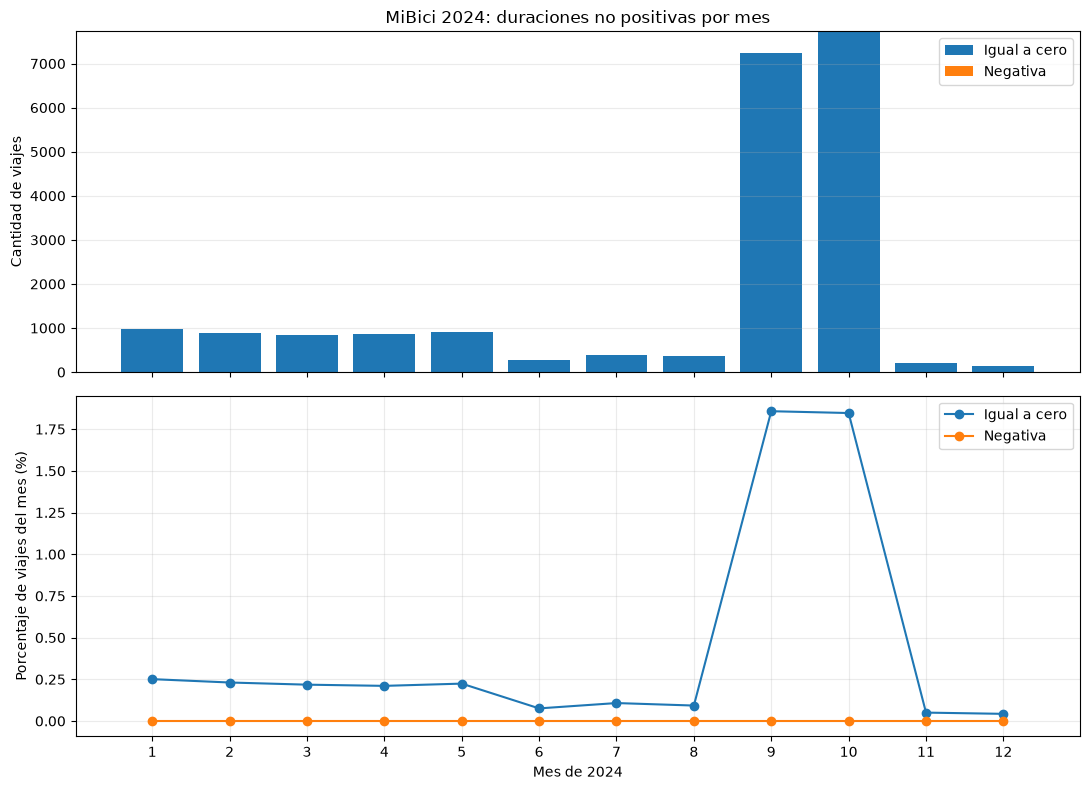

In [10]:
import matplotlib.pyplot as plt

# Frecuencia y tasa, para evitar comparar solo conteos entre meses de distinto tamaño.
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
meses = duraciones_detalle_df["mes"].astype(int).tolist()
axes[0].bar(meses, duraciones_detalle_df["duracion_cero"], label="Igual a cero")
axes[0].bar(meses, duraciones_detalle_df["duracion_negativa"],
            bottom=duraciones_detalle_df["duracion_cero"], label="Negativa")
axes[0].set_ylabel("Cantidad de viajes")
axes[0].set_title("MiBici 2024: duraciones no positivas por mes")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)
axes[1].plot(meses, 100 * duraciones_detalle_df["duracion_cero"] / duraciones_detalle_df["viajes"],
             marker="o", label="Igual a cero")
axes[1].plot(meses, 100 * duraciones_detalle_df["duracion_negativa"] / duraciones_detalle_df["viajes"],
             marker="o", label="Negativa")
axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel("Mes de 2024")
axes[1].set_ylabel("Porcentaje de viajes del mes (%)")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Interpretación de las duraciones no positivas (2.3.1).** De los **4,645,921 viajes** se observaron **20,850 duraciones exactamente iguales a cero (0.449 %)** y **ninguna duración negativa**. Septiembre y octubre, cuyos archivos registran fechas con precisión de minutos, reúnen **14,978** de los ceros (71.8 % del total de ceros). Su tasa conjunta de ceros es aproximadamente **1.852 %**, frente a **0.153 %** en los otros diez meses. Esta asociación es compatible con pérdida de precisión al registrar el tiempo, pero **no confirma la validez operativa** de cada registro. Los viajes de duración cero se conservan en los CSV originales; para un primer modelo que prediga una duración *positiva* pueden excluirse del conjunto de entrenamiento mediante una regla documentada, sin confundirlos con duraciones negativas ni extrapolar esta decisión a P1–P3 indiscriminadamente.

### 2.3.2 Revisión individual de viajes con duración superior a 24 horas

El diagnóstico de 2.3 identifica **13 registros** con duración superior a 24 horas. Antes de decidir si excluirlos del entrenamiento, revisamos sus fechas, duración en horas, mes de origen y estaciones. La extracción se hace por bloques y **no muestra identificadores de usuario ni otros campos demográficos**. Los CSV originales permanecen intactos.

**Criterios de interpretación:** verificar si las fechas son coherentes, si el viaje atraviesa días o meses y si las duraciones son apenas mayores a 24 horas o alcanzan varios días. Una duración larga no demuestra por sí sola un error de captura ni un viaje legítimo. No se aplica ningún filtro de entrenamiento en esta sección.


In [11]:
# 2.3.2 Inspección de viajes con duración superior a 24 horas
# Reutiliza los lectores y el manejo de fechas establecidos en la sección 2.
casos_mayores_24h = []

for path in FILES:
    for mes, bloque in bloques_mibici(path):
        inicio = interpretar_fechas(bloque["inicio"], mes)
        fin = interpretar_fechas(bloque["fin"], mes)
        horas = (fin - inicio).dt.total_seconds() / 3600
        filtro = inicio.notna() & fin.notna() & horas.gt(LIMITE_DURACION_HORAS)

        if filtro.any():
            casos_mayores_24h.append(pd.DataFrame({
                "mes_archivo": mes,
                "inicio": inicio.loc[filtro].to_numpy(),
                "fin": fin.loc[filtro].to_numpy(),
                "duracion_horas": horas.loc[filtro].to_numpy(),
                "estacion_origen": bloque.loc[filtro, "origen"].to_numpy(),
                "estacion_destino": bloque.loc[filtro, "destino"].to_numpy(),
            }))

columnas_extremos = [
    "mes_archivo", "inicio", "fin", "duracion_horas",
    "estacion_origen", "estacion_destino"
]
if casos_mayores_24h:
    extremos_24h_df = pd.concat(casos_mayores_24h, ignore_index=True)
    extremos_24h_df = extremos_24h_df.sort_values(
        "duracion_horas", ascending=False
    ).reset_index(drop=True)
else:
    extremos_24h_df = pd.DataFrame(columns=columnas_extremos)

esperados_24h = int(tiempo_df["duracion_mayor_24h"].sum())
assert len(extremos_24h_df) == esperados_24h, (
    f"Inconsistencia con 2.3: encontrados={len(extremos_24h_df)}, "
    f"esperados={esperados_24h}"
)

print(f"Viajes mayores a {LIMITE_DURACION_HORAS} h: {len(extremos_24h_df)}")
if not extremos_24h_df.empty:
    display(extremos_24h_df.assign(
        duracion_horas=lambda d: d["duracion_horas"].round(2)
    ))
    print("Duración mínima (h):", round(extremos_24h_df["duracion_horas"].min(), 2))
    print("Duración mediana (h):", round(extremos_24h_df["duracion_horas"].median(), 2))
    print("Duración máxima (h):", round(extremos_24h_df["duracion_horas"].max(), 2))
    print("Casos por mes:")
    display(extremos_24h_df.groupby("mes_archivo").size().rename("casos").to_frame())
    print("Viajes que cruzan a otro día:", int(
        (extremos_24h_df["inicio"].dt.date != extremos_24h_df["fin"].dt.date).sum()
    ))
    print("Viajes que cruzan a otro mes:", int(
        (extremos_24h_df["inicio"].dt.to_period("M") !=
         extremos_24h_df["fin"].dt.to_period("M")).sum()
    ))


Viajes mayores a 24 h: 13


,mes_archivo,inicio,fin,duracion_horas,estacion_origen,estacion_destino
0,11,2024-11-15 18:02:13,2024-11-19 06:36:59,84.58,176,281
1,10,2024-10-14 12:25:00,2024-10-16 17:07:00,52.70,11,208
2,9,2024-09-21 14:42:00,2024-09-23 18:32:00,51.83,40,47
3,1,2024-01-20 12:39:47,2024-01-22 12:17:23,47.63,44,44
4,9,2024-09-28 12:17:00,2024-09-30 10:43:00,46.43,197,172
5,4,2024-04-22 18:24:42,2024-04-24 12:04:03,41.66,293,340
6,8,2024-08-12 09:29:44,2024-08-13 18:36:14,33.11,175,2
7,7,2024-07-20 11:42:25,2024-07-21 15:41:14,27.98,75,75
8,4,2024-04-05 10:18:02,2024-04-06 13:54:54,27.61,216,49
9,10,2024-10-06 11:39:00,2024-10-07 13:35:00,25.93,54,83


Duración mínima (h): 24.65
Duración mediana (h): 33.11
Duración máxima (h): 84.58
Casos por mes:


,casos
mes_archivo,
1,2
4,2
7,2
8,1
9,2
10,2
11,2


Viajes que cruzan a otro día: 13
Viajes que cruzan a otro mes: 0


**Interpretación de los 13 viajes mayores a 24 horas (2.3.2).** La revisión individual confirmó **13 registros (aproximadamente 0.00028 % de los 4,645,921 viajes)** con duración entre **24.65 y 84.58 horas**; la **mediana fue 33.11 horas**. Los 13 tienen fecha de fin posterior a la de inicio, **cruzan al día siguiente o posteriores**, pero **ninguno cruza de mes**. Se distribuyen en enero, abril, julio, agosto, septiembre, octubre y noviembre: no se limitan a los meses de menor resolución temporal. Tres empiezan y terminan en la misma estación, lo que por sí solo no constituye una anomalía demostrada.

Los CSV **no permiten determinar** si estos intervalos representan alquileres extraordinariamente largos, demoras de devolución o incidencias operativas; por tanto, **no se etiquetan automáticamente como errores** ni se eliminan del origen.

**Política preliminar para una regresión de duración habitual:** usar como baseline registros con duración **mayor que cero y menor o igual a 24 horas**; conservar documentados los 13 casos excluidos de ese entrenamiento y registrar la regla (`0 < duracion_horas <= 24`) y los conteos en MLflow. Para justificar el umbral, contrastarlo con una variante que incluya **todas las duraciones positivas**, manteniendo particiones comparables y evaluando ambas variantes sobre **el mismo conjunto de prueba de viajes habituales**. Reportar de forma separada el desempeño o la cobertura sobre los viajes extremos, ya que filtrarlos también del test ocultaría ese comportamiento. Esta recomendación se aplica al objetivo de *duración habitual*, no automáticamente a clasificación ni clustering.

*Esta sección es diagnóstica: no cambia los CSV, no aplica filtros de entrenamiento y no permite afirmar que los 13 casos sean inválidos.*

## 2.4 Consistencia de estaciones de origen y destino

Se comparan los IDs observados en los viajes con la nomenclatura disponible de **septiembre de 2026**. Esta correspondencia es útil para verificar claves, pero no prueba ubicación, existencia, nombre o capacidad histórica en 2024. No se publican identificadores personales.

In [12]:
catalogo_ids = set(nomenclatura["id"].dropna().astype("string").str.strip())
estaciones_rows = []
for path in FILES:
    c = Counter()
    for mes, bloque in bloques_mibici(path):
        c["viajes"] += len(bloque)
        for campo in ("origen", "destino"):
            v = bloque[campo]
            c[f"{campo}_faltante"] += int(v.isna().sum())
            c[f"{campo}_sin_catalogo"] += int((v.notna() & ~v.isin(catalogo_ids)).sum())
        c["mismo_origen_destino"] += int((bloque.origen.notna() & bloque.destino.notna() & (bloque.origen == bloque.destino)).sum())
    estaciones_rows.append({"mes": int(path.stem[-2:]), **dict(c)})

estaciones_df = pd.DataFrame(estaciones_rows).sort_values("mes").fillna(0)
display(estaciones_df)
print("Incidencias anuales:")
display(estaciones_df.drop(columns="mes").sum().to_frame("total").T)
print("Nota: igual origen/destino no equivale necesariamente a viaje inválido.")

,mes,viajes,origen_faltante,origen_sin_catalogo,destino_faltante,destino_sin_catalogo,mismo_origen_destino
0,1,391591,0,0,0,0,27039
1,2,383732,0,0,0,0,26508
2,3,390513,0,0,0,0,28531
3,4,405308,0,0,0,0,28919
4,5,410806,0,0,0,0,28000
5,6,365000,0,0,0,0,22538
6,7,364177,0,0,0,0,23440
7,8,394894,0,0,0,0,24290
8,9,390072,0,0,0,0,23703
9,10,418690,0,0,0,0,24898


Incidencias anuales:


,viajes,origen_faltante,origen_sin_catalogo,destino_faltante,destino_sin_catalogo,mismo_origen_destino
total,4645921,0,0,0,0,300820


Nota: igual origen/destino no equivale necesariamente a viaje inválido.


## 2.5 Distribución de variables categóricas y anomalías iniciales

Se resume `genero` como categoría agregada (incluidos faltantes), junto con el año de nacimiento. Para no publicar información individual, las salidas se limitan a conteos por categoría y rangos de edad. **No se infiere ninguna característica personal a partir de categorías faltantes o inesperadas.**

In [13]:
genero_conteo = Counter()
anios_conteo = Counter()
for path in FILES:
    for _, bloque in bloques_mibici(path):
        genero_conteo.update(bloque["genero"].fillna("<FALTANTE>").astype(str).tolist())
        nac = pd.to_numeric(bloque["anio_nacimiento"], errors="coerce")
        anios_conteo["anio_faltante_o_invalido"] += int(nac.isna().sum())
        anios_conteo["anio_posterior_2024"] += int(nac.gt(2024).sum())
        anios_conteo["edad_fuera_16_a_100"] += int(((2024 - nac).lt(16) | (2024 - nac).gt(100)).sum())
        anios_conteo["anio_valido_edad_16_a_100"] += int(((2024 - nac).ge(16) & (2024 - nac).le(100)).sum())

categoria_df = pd.DataFrame(genero_conteo.items(), columns=["categoria_genero", "viajes"]).sort_values("viajes", ascending=False)
display(categoria_df)
display(pd.DataFrame([anios_conteo]))
print("Advertencia: los rangos de edad son criterios exploratorios, no filtros aplicados.")

,categoria_genero,viajes
0,M,3364522
1,F,1252453
2,<FALTANTE>,28946


,anio_faltante_o_invalido,anio_posterior_2024,edad_fuera_16_a_100,anio_valido_edad_16_a_100
0,2667,0,1163,4642091


Advertencia: los rangos de edad son criterios exploratorios, no filtros aplicados.


## 2.6 Diagnóstico consolidado y decisiones preliminares

La siguiente tabla reúne incidencias reportadas por los análisis anteriores. **Las categorías pueden solaparse** (un mismo viaje puede tener varias incidencias), por lo que no deben sumarse para contar viajes únicos inválidos. Las decisiones de limpieza se definirán conforme a la pregunta y momento de predicción; por ahora no se descarta ningún registro original.

In [14]:
indicadores = [
    ("Viajes originales 2024", int(resumen["viajes"].sum())),
    ("Filas exactas repetidas", int(dup_exactos)),
    ("IDs de viaje repetidos", int(ids_repetidos)),
    ("Inicio inválido", int(tiempo_df["inicio_invalido"].sum())),
    ("Fin inválido", int(tiempo_df["fin_invalido"].sum())),
    ("Duración no positiva", int(tiempo_df["duracion_no_positiva"].sum())),
    ("Duración mayor de 24 h", int(tiempo_df["duracion_mayor_24h"].sum())),
    ("Inicio fuera del mes de archivo", int(tiempo_df["inicio_fuera_mes"].sum())),
    ("Origen no presente en catálogo 2026", int(estaciones_df["origen_sin_catalogo"].sum())),
    ("Destino no presente en catálogo 2026", int(estaciones_df["destino_sin_catalogo"].sum())),
]
diagnostico_df = pd.DataFrame(indicadores, columns=["indicador", "conteo"])
display(diagnostico_df)
print("Los conteos se solapan: no representan un total de filas a eliminar.")

,indicador,conteo
0,Viajes originales 2024,4645921
1,Filas exactas repetidas,0
2,IDs de viaje repetidos,0
3,Inicio inválido,0
4,Fin inválido,0
5,Duración no positiva,20850
6,Duración mayor de 24 h,13
7,Inicio fuera del mes de archivo,0
8,Origen no presente en catálogo 2026,0
9,Destino no presente en catálogo 2026,0


Los conteos se solapan: no representan un total de filas a eliminar.


### 2.6.1 Visualización de incidencias y proporciones

Las gráficas comparan **porcentajes** cuando los tamaños mensuales son distintos. Las ausencias por campo pueden corresponder a un mismo viaje y, por tanto, **no deben sumarse** para inferir registros a descartar.

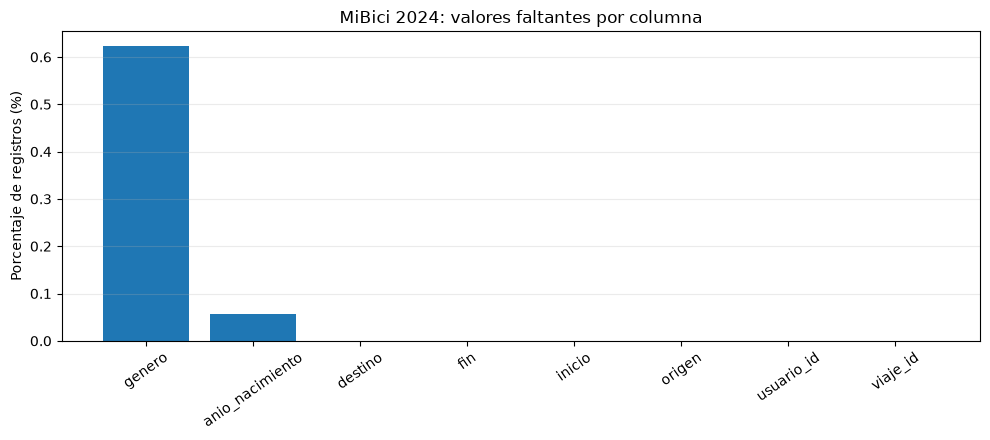

In [15]:
# Comparación de faltantes por campo a escala anual.
import matplotlib.pyplot as plt
faltantes_anuales = (faltantes_df.groupby("campo", as_index=False)
                     .agg(faltantes=("faltantes", "sum"), registros=("registros", "sum")))
faltantes_anuales["pct"] = 100 * faltantes_anuales["faltantes"] / faltantes_anuales["registros"]
faltantes_anuales = faltantes_anuales.sort_values("pct", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(faltantes_anuales["campo"], faltantes_anuales["pct"])
ax.set_title("MiBici 2024: valores faltantes por columna")
ax.set_ylabel("Porcentaje de registros (%)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


In [16]:
# Síntesis automática: se calcula con las salidas obtenidas en la ejecución actual.
viajes = int(resumen["viajes"].sum())
ceros = int(duraciones_detalle_df["duracion_cero"].sum())
negativas = int(duraciones_detalle_df["duracion_negativa"].sum())
print("RESUMEN DE HALLAZGOS — MIBICI 2024")
print(f"Viajes revisados: {viajes:,}")
print(f"Duplicados exactos: {dup_exactos:,}; IDs de viaje repetidos: {ids_repetidos:,}")
print(f"Duraciones cero: {ceros:,} ({100*ceros/viajes:.3f} %)")
print(f"Duraciones negativas: {negativas:,} ({100*negativas/viajes:.3f} %)")
print(f"Duraciones mayores a 24 h: {int(tiempo_df['duracion_mayor_24h'].sum()):,}")
for campo in ["genero", "anio_nacimiento"]:
    fila = faltantes_anuales.loc[faltantes_anuales["campo"].eq(campo)]
    if not fila.empty:
        print(f"Faltantes en {campo}: {int(fila.iloc[0]['faltantes']):,} ({float(fila.iloc[0]['pct']):.3f} %)")
print("Nota: los indicadores pueden superponerse; no son un conteo de filas a eliminar.")


RESUMEN DE HALLAZGOS — MIBICI 2024
Viajes revisados: 4,645,921
Duplicados exactos: 0; IDs de viaje repetidos: 0
Duraciones cero: 20,850 (0.449 %)
Duraciones negativas: 0 (0.000 %)
Duraciones mayores a 24 h: 13
Faltantes en genero: 28,946 (0.623 %)
Faltantes en anio_nacimiento: 2,667 (0.057 %)
Nota: los indicadores pueden superponerse; no son un conteo de filas a eliminar.


### Conclusiones y recomendaciones para MLOps

1. **Integridad y trazabilidad.** Se analizaron **4,645,921 viajes de 2024** procedentes de 12 CSV. Conservar los originales sin modificaciones y verificar esquema, volumen y SHA-256 para reproducir la ingesta.
2. **Duplicados.** No se detectaron filas completamente duplicadas ni identificadores de viaje repetidos entre los doce meses. Mantener estas comprobaciones como validaciones automáticas de ingesta.
3. **Consistencia temporal.** Se obtuvieron **20,850 duraciones exactamente cero (0.449 %)** y **ninguna negativa**. Septiembre y octubre registran fechas con precisión de minutos y concentran 14,978 duraciones cero; esta asociación sugiere una pérdida de precisión, pero no prueba que los registros sean válidos. Para regresión de duración positiva, documentar la exclusión preliminar de ceros del entrenamiento; no modificar los datos crudos.
4. **Viajes mayores a 24 horas.** Se investigaron **13 casos**, con duraciones de **24.65 a 84.58 h** (mediana **33.11 h**). Todos tienen secuencia temporal coherente y ninguno cruza de mes; su validez operativa no puede determinarse solo con los CSV. **Propuesta provisional para un baseline de duración habitual:** entrenar con `0 < duracion_horas <= 24` y contrastar con un entrenamiento que incluya todas las duraciones positivas. Mantener una evaluación comparable en un mismo test de viajes habituales y analizar aparte los extremos; registrar el umbral y los casos afectados en MLflow. No aplicar el filtro indiscriminadamente a P1–P3.
5. **Faltantes y variables demográficas.** Se detectaron **28,946 valores faltantes en género** y **2,667 en año de nacimiento**. Tratar su pertinencia y ausencia según la pregunta predictiva; no eliminar viajes completos automáticamente por estos campos.
6. **Estaciones y contexto histórico.** Se observaron **370 IDs de estaciones** y los 370 aparecen en el catálogo de septiembre de 2026; ello no garantiza que las capacidades o ubicaciones del catálogo sean históricamente idénticas en 2024. Evitar incorporar información posterior al momento de predicción.
7. **Código reproducible.** Trasladar las reglas acordadas y las validaciones a funciones de `mibici/dataset.py` y `mibici/features.py`, con configuración centralizada en `mibici/config.py`. Registrar en MLflow versión y periodo de datos, semilla, parámetros, métricas separadas por partición, modelo y commit de Git.
8. **Privacidad y Git.** Excluir del historial CSV originales y procesados, base SQLite temporal, identificadores de usuario, credenciales, modelos y directorios de MLflow. Verificar `.gitignore` antes de integrar el notebook mediante Pull Request.

**Alcance:** estas son conclusiones del EDA y **reglas de preparación propuestas**, aún no ejecutadas como pipeline de entrenamiento. Su aplicación definitiva dependerá de las preguntas P1–P3 y de la evaluación de los baselines.